In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# VAR(p)
## Vector autoregression
VAR predicts several series jointly from their lagged values. Predictive dependence in both directions does not establish causality.

However, there are some cases where variables affect each other. <a href='https://otexts.com/fpp2/VAR.html'>Forecasting: Principles and Practice</a> describes a case where changes in personal consumption expenditures $C_t$ were forecast based on changes in personal disposable income $I_t$.
> However, in this case a bi-directional relationship may be more suitable: an increase in $I_t$ will lead to an increase in $C_t$ and vice versa.<br>An example of such a situation occurred in Australia during the Global Financial Crisis of 2008–2009. The Australian government issued stimulus packages that included cash payments in December 2008, just in time for Christmas spending. As a result, retailers reported strong sales and the economy was stimulated. Consequently, incomes increased.

Aside from investigating multivariate time series, vector autoregression is used for
* <a href='https://www.statsmodels.org/devel/vector_ar.html#impulse-response-analysis'>Impulse Response Analysis</a> which involves the response of one variable to a sudden but temporary change in another variable
* <a href='https://www.statsmodels.org/devel/vector_ar.html#forecast-error-variance-decomposition-fevd'>Forecast Error Variance Decomposition (FEVD)</a> where the proportion of the forecast variance of one variable is attributed to the effect of other variables
* <a href='https://www.statsmodels.org/devel/vector_ar.html#dynamic-vector-autoregressions'>Dynamic Vector Autoregressions</a> used for estimating a moving-window regression for the purposes of making forecasts throughout the data sample

### Formulation
We've seen that an autoregression AR(p) model is described by the following:

&nbsp;&nbsp;&nbsp;&nbsp; $y_{t} = c + \phi_{1}y_{t-1} + \phi_{2}y_{t-2} + \dots + \phi_{p}y_{t-p} + \varepsilon_{t}$

where $c$ is a constant, $\phi_{1}$ and $\phi_{2}$ are lag coefficients up to order $p$, and $\varepsilon_{t}$ is white noise.

A $K$-dimensional VAR model of order $p$, denoted <strong>VAR(p)</strong>, considers each variable $y_K$ in the system.<br>

For example, The system of equations for a 2-dimensional VAR(1) model is:

&nbsp;&nbsp;&nbsp;&nbsp;$y_{1,t} = c_1 + \phi_{11,1}y_{1,t-1} + \phi_{12,1}y_{2,t-1} + \varepsilon_{1,t}$<br>
&nbsp;&nbsp;&nbsp;&nbsp;$y_{2,t} = c_2 + \phi_{21,1}y_{1,t-1} + \phi_{22,1}y_{2,t-1} + \varepsilon_{2,t}$

where the coefficient $\phi_{ii,l}$ captures the influence of the $l$th lag of variable $y_i$ on itself,<br>
the coefficient $\phi_{ij,l}$ captures the influence of the $l$th lag of variable $y_j$ on $y_i$,<br>
and $\varepsilon_{1,t}$ and $\varepsilon_{2,t}$ are white noise processes that may be correlated.<br>

Carrying this further, the system of equations for a 2-dimensional VAR(3) model is:

&nbsp;&nbsp;&nbsp;&nbsp;$y_{1,t} = c_1 + \phi_{11,1}y_{1,t-1} + \phi_{12,1}y_{2,t-1} + \phi_{11,2}y_{1,t-2} + \phi_{12,2}y_{2,t-2} + \phi_{11,3}y_{1,t-3} + \phi_{12,3}y_{2,t-3} + \varepsilon_{1,t}$<br>
&nbsp;&nbsp;&nbsp;&nbsp;$y_{2,t} = c_2 + \phi_{21,1}y_{1,t-1} + \phi_{22,1}y_{2,t-1} + \phi_{21,2}y_{1,t-2} + \phi_{22,2}y_{2,t-2} + \phi_{21,3}y_{1,t-3} + \phi_{22,3}y_{2,t-3} + \varepsilon_{2,t}$<br><br>

and the system of equations for a 3-dimensional VAR(2) model is:

&nbsp;&nbsp;&nbsp;&nbsp;$y_{1,t} = c_1 + \phi_{11,1}y_{1,t-1} + \phi_{12,1}y_{2,t-1} + \phi_{13,1}y_{3,t-1} + \phi_{11,2}y_{1,t-2} + \phi_{12,2}y_{2,t-2} + \phi_{13,2}y_{3,t-2} + \varepsilon_{1,t}$<br>
&nbsp;&nbsp;&nbsp;&nbsp;$y_{2,t} = c_2 + \phi_{21,1}y_{1,t-1} + \phi_{22,1}y_{2,t-1} + \phi_{23,1}y_{3,t-1} + \phi_{21,2}y_{1,t-2} + \phi_{22,2}y_{2,t-2} + \phi_{23,2}y_{3,t-2} + \varepsilon_{2,t}$<br>
&nbsp;&nbsp;&nbsp;&nbsp;$y_{3,t} = c_3 + \phi_{31,1}y_{1,t-1} + \phi_{32,1}y_{2,t-1} + \phi_{33,1}y_{3,t-1} + \phi_{31,2}y_{1,t-2} + \phi_{32,2}y_{2,t-2} + \phi_{33,2}y_{3,t-2} + \varepsilon_{3,t}$<br><br>

The general steps involved in building a VAR model are:
* Examine the data
* Visualize the data
* Test for stationarity
* If necessary, transform the data to make it stationary
* Select the appropriate order <em>p</em>
* Instantiate the model and fit it to a training set
* If necessary, invert the earlier transformation
* Evaluate model predictions against a known test set
* Forecast the future

With VAR, both series are endogenous: their lagged values appear in each forecasting equation.

<div class="alert alert-info"><h3>Related functions</h3>

- [VAR and lag-order selection](https://www.statsmodels.org/stable/generated/statsmodels.tsa.vector_ar.var_model.VAR.html)
- [VAR results and forecasting](https://www.statsmodels.org/stable/generated/statsmodels.tsa.vector_ar.var_model.VARResults.html)
- [Statsmodels VAR tutorial](https://www.statsmodels.org/stable/vector_ar.html)

</div>

In [2]:
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tools.eval_measures import rmse

df = pd.read_csv('../../Excercise_data/L08/M2SLMoneyStock.csv', index_col=0, parse_dates=True)
sp = pd.read_csv('../../Excercise_data/L08/PCEPersonalSpending.csv', index_col=0, parse_dates=True)
df.index.freq = 'MS'
sp.index.freq = 'MS'

In [3]:
df = df.join(sp)
df.head()

,Money,Spending
Date,,
1995-01-01,3492.4,4851.2
1995-02-01,3489.9,4850.8
1995-03-01,3491.1,4885.4
1995-04-01,3499.2,4890.2
1995-05-01,3524.2,4933.1


In [4]:
df = df.dropna()
nobs = 12
train_levels = df.iloc[:-nobs].copy()
test_levels = df.iloc[-nobs:].copy()
print('Training:', train_levels.index.min(), 'to', train_levels.index.max())
print('Test:', test_levels.index.min(), 'to', test_levels.index.max())

Training: 1995-01-01 00:00:00 to 2014-12-01 00:00:00
Test: 2015-01-01 00:00:00 to 2015-12-01 00:00:00


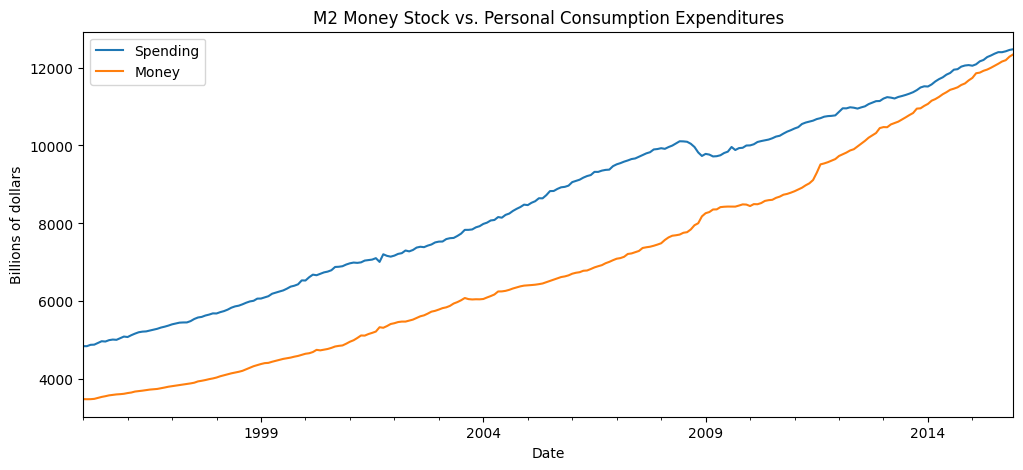

In [5]:
title = 'M2 Money Stock vs. Personal Consumption Expenditures'
ylabel='Billions of dollars'
xlabel=''

ax = df['Spending'].plot(figsize=(12,5),title=title,legend=True)
ax.autoscale(axis='x',tight=True)
ax.set(xlabel=xlabel, ylabel=ylabel)
df['Money'].plot(legend=True);

## Training-only stationarity diagnostics
Choose transformations and lag order using the training period. Keep the final 12 months out of those decisions.

In [6]:
def adf_test(series, title=''):
    result = adfuller(series.dropna(), autolag='AIC')
    print(f'{title}: ADF={result[0]:.3f}, p={result[1]:.4f}')
    if result[1] <= 0.05:
        print('Evidence against the unit-root null for this specification.')
    else:
        print('The unit-root null is not rejected; this does not prove a unit root.')

In [7]:
adf_test(train_levels['Money'], title='Money')

Money: ADF=4.045, p=1.0000
The unit-root null is not rejected; this does not prove a unit root.


In [8]:
adf_test(train_levels['Spending'], title='Spending')

Spending: ADF=0.065, p=0.9636
The unit-root null is not rejected; this does not prove a unit root.


Compare first differences using training data. ADF alone does not certify stationarity. Keep the levels: forecasts must return to their original units for evaluation.

In [9]:
first_differences = train_levels.diff().dropna()
adf_test(first_differences['Money'], 'Money: first difference')
adf_test(first_differences['Spending'], 'Spending: first difference')

Money: first difference: ADF=-4.458, p=0.0002
Evidence against the unit-root null for this specification.
Spending: first difference: ADF=-6.961, p=0.0000
Evidence against the unit-root null for this specification.


Compare second differences as a diagnostic, then use **first differences of both series** as this worked specification. Orders do not have to match: differently transformed columns can be aligned by date. Over-differencing can damage forecasts.

This is a baseline, not a claim that these tests establish an optimal model. For cointegrated levels, a VECM can retain long-run relationships.

In [10]:
second_differences = first_differences.diff().dropna()
adf_test(second_differences['Money'], 'Money: second difference')
adf_test(second_differences['Spending'], 'Spending: second difference')

Money: second difference: ADF=-6.686, p=0.0000
Evidence against the unit-root null for this specification.
Spending: second difference: ADF=-8.414, p=0.0000
Evidence against the unit-root null for this specification.


### Retain the selected training transformation
The test period stays in levels and is used only after forecast inversion.

In [11]:
train = first_differences

## VAR model order selection
Compare lags 0-7 by AIC on a common effective training sample. BIC may prefer a different order. Refit the AIC-selected order on all training differences.

In [12]:
model = VAR(train)
order_selection = model.select_order(maxlags=7)
print(order_selection.summary())
selected_order = order_selection.selected_orders['aic']
print('AIC-selected lag order:', selected_order)

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0       13.88       13.91   1.069e+06       13.89
1       13.74      13.83*   9.238e+05       13.77
2       13.71       13.86   9.026e+05       13.77
3       13.69       13.90   8.861e+05       13.78
4      13.66*       13.92  8.518e+05*      13.76*
5       13.66       13.99   8.598e+05       13.80
6       13.66       14.05   8.589e+05       13.82
7       13.68       14.13   8.745e+05       13.86
-------------------------------------------------
AIC-selected lag order: 4


The selected order comes from training data. Check that both series enter the model.

In [13]:
model.endog_names

['Money', 'Spending']

In [14]:
results = model.fit(selected_order)
print('Stable fitted VAR:', results.is_stable())
results.summary()

Stable fitted VAR: True


  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Fri, 30, Oct, 2026
Time:                     15:08:21
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                    13.9008
Nobs:                     235.000    HQIC:                   13.7427
Log likelihood:          -2251.11    FPE:                    835602.
AIC:                      13.6358    Det(Omega_mle):         775097.
--------------------------------------------------------------------
Results for equation Money
                 coefficient       std. error           t-stat            prob
------------------------------------------------------------------------------
const              16.324822         4.886231            3.341           0.001
L1.Money            0.276445         0.066475            4.159           0.000
L1.Spending        -0.097870         0.051726           -1.892      

## Forecast the next 12 months
Supply the final training lag observations. The forecast contains differences; use the held-out dates only as its index.

In [15]:
lag_order = results.k_ar
lag_order

4

In [16]:
if lag_order == 0:
    z = np.tile(results.params.loc['const'].to_numpy(), (nobs, 1))
else:
    z = results.forecast(y=train.values[-lag_order:], steps=nobs)
z

array([[53.33230197, 40.11955075],
       [50.58914474, 27.35888278],
       [50.50701988, 27.85128809],
       [39.89400849, 26.50987069],
       [42.73045282, 27.40533516],
       [40.53375454, 27.96549257],
       [37.63282684, 27.8917967 ],
       [37.76085864, 28.50361209],
       [36.8456832 , 28.68582974],
       [36.0798585 , 28.98269002],
       [35.94828264, 29.28409936],
       [35.6412045 , 29.45370113]])

In [17]:
df_forecast = pd.DataFrame(z, index=test_levels.index, columns=['Money1d', 'Spending1d'])
df_forecast

,Money1d,Spending1d
Date,,
2015-01-01,53.332302,40.119551
2015-02-01,50.589145,27.358883
2015-03-01,50.507020,27.851288
2015-04-01,39.894008,26.509871
2015-05-01,42.730453,27.405335
2015-06-01,40.533755,27.965493
2015-07-01,37.632827,27.891797
2015-08-01,37.760859,28.503612
2015-09-01,36.845683,28.685830


## Invert the transformation
Add the cumulative sum of predicted first differences to the final observed training level. Do not use test observations as initial values.

In [18]:
df_forecast['MoneyForecast'] = train_levels['Money'].iloc[-1] + df_forecast['Money1d'].cumsum()

In [19]:
df_forecast['SpendingForecast'] = train_levels['Spending'].iloc[-1] + df_forecast['Spending1d'].cumsum()

In [20]:
df_forecast

,Money1d,Spending1d,MoneyForecast,SpendingForecast
Date,,,,
2015-01-01,53.332302,40.119551,11723.432302,12102.119551
2015-02-01,50.589145,27.358883,11774.021447,12129.478434
2015-03-01,50.507020,27.851288,11824.528467,12157.329722
2015-04-01,39.894008,26.509871,11864.422475,12183.839592
2015-05-01,42.730453,27.405335,11907.152928,12211.244927
2015-06-01,40.533755,27.965493,11947.686682,12239.210420
2015-07-01,37.632827,27.891797,11985.319509,12267.102217
2015-08-01,37.760859,28.503612,12023.080368,12295.605829
2015-09-01,36.845683,28.685830,12059.926051,12324.291659


## Plot the results
The VARResults object offers a couple of quick plotting tools:

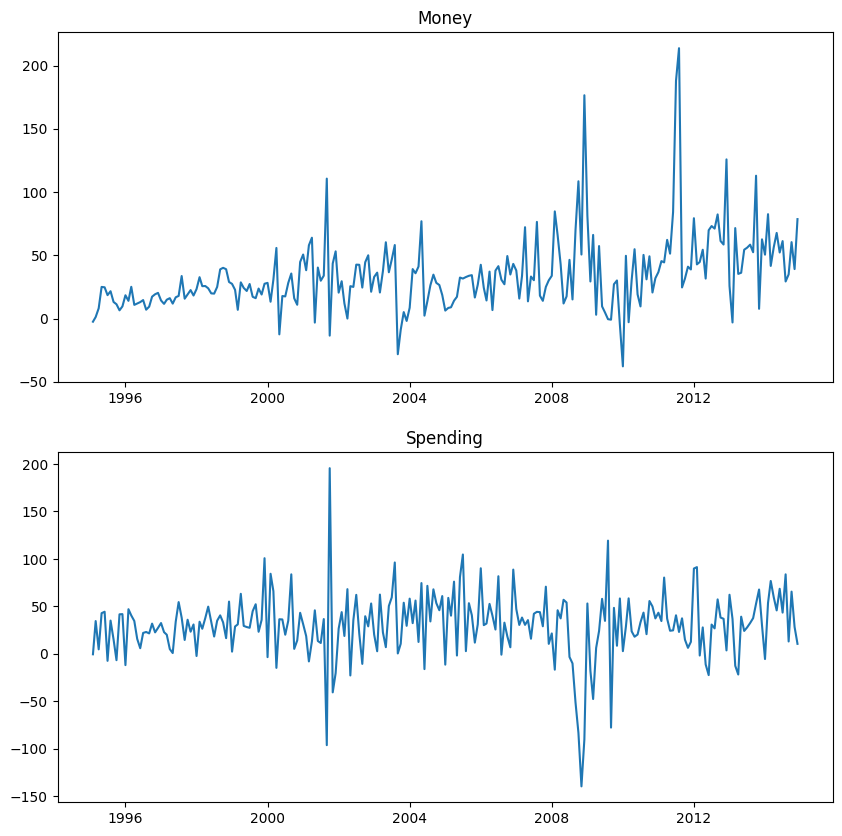

In [21]:
results.plot();

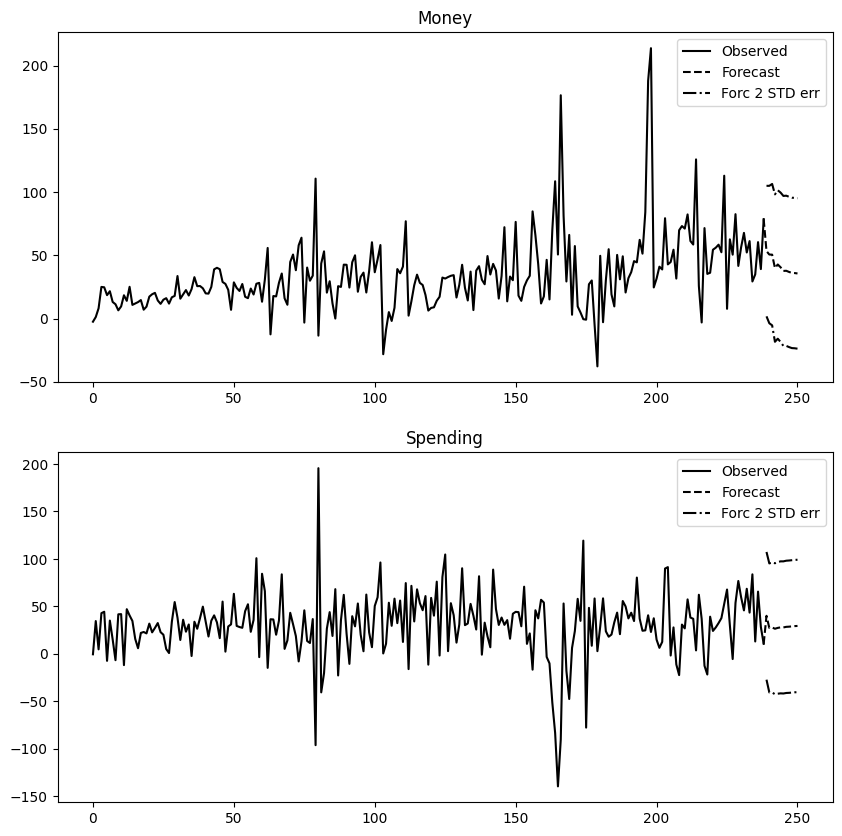

In [22]:
if lag_order > 0:
    results.plot_forecast(nobs);

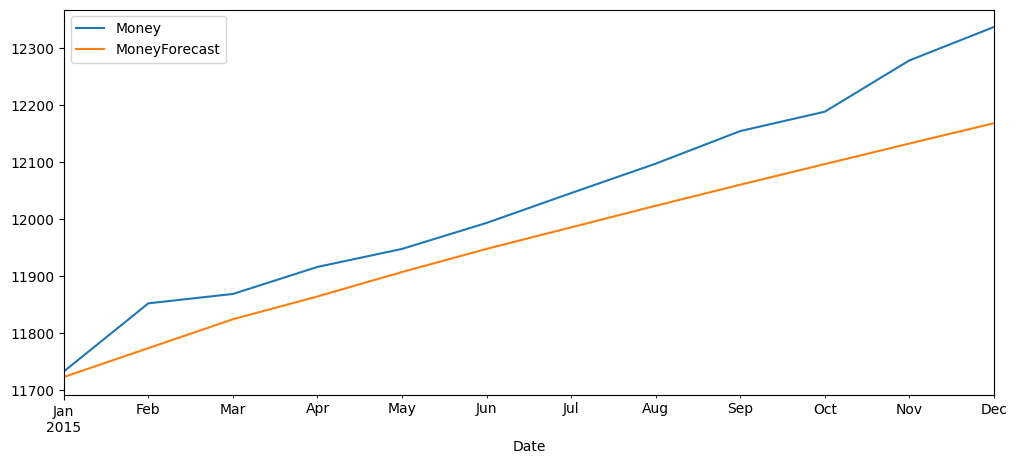

In [23]:
df['Money'][-nobs:].plot(figsize=(12,5),legend=True).autoscale(axis='x',tight=True)
df_forecast['MoneyForecast'].plot(legend=True);

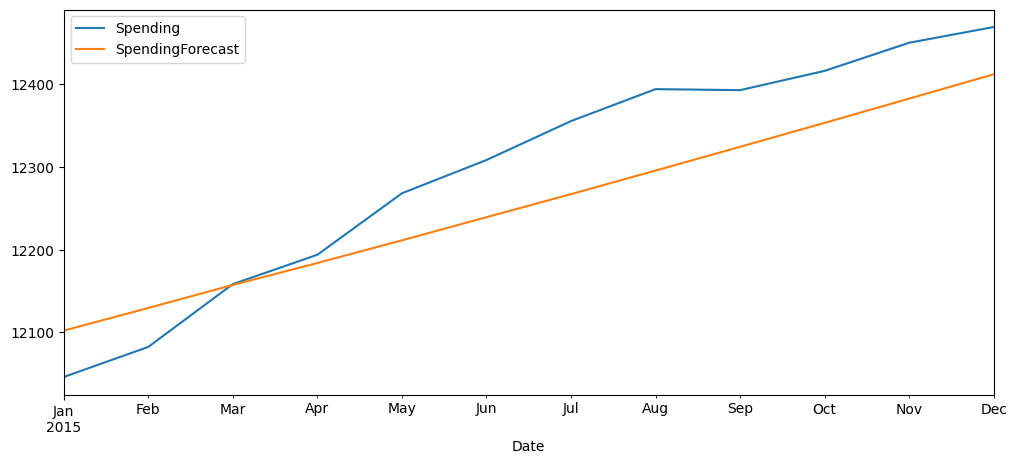

In [24]:
df['Spending'][-nobs:].plot(figsize=(12,5),legend=True).autoscale(axis='x',tight=True)
df_forecast['SpendingForecast'].plot(legend=True);

### Evaluate model

In [25]:
money_rmse = rmse(test_levels['Money'], df_forecast['MoneyForecast'])
spending_rmse = rmse(test_levels['Spending'], df_forecast['SpendingForecast'])
print(f'Spending VAR({selected_order}) RMSE: {spending_rmse:.3f}')
print(f'Money VAR({selected_order}) RMSE: {money_rmse:.3f}')

Spending VAR(4) RMSE: 62.856
Money VAR(4) RMSE: 86.747


### Optional: refit and forecast beyond the dataset
After documenting held-out results, refit the same specification on all available monthly data and forecast the next 12 months. Invert differences from the final observed level. No future targets are provided, so do not report a future RMSE.